# Statistical Analysis — Household Energy Footprint

Loads the pre-computed `var_for_stat_analysis_<n>COICOP.pkl` produced by `Household_EF.py` / `Household_EF.ipynb` (Cell 12). Run that script first if the file does not exist.

The pickle holds one row per SHS 2019 survey household with:
- **Identifier**: `CaseID`
- **Weights / scale**: `WeightD`, `OECD_scale`, `OECD_cap`
- **Income**: `HH_TotInc`, `Inc_hh_dec`, `Inc_OECDcap_dec`
- **Socio-demographic**: `Prov`, `HHType6`, `RP_AgeGrp`, `RP_Gender`, `RP_MarStat`, `RP_Educ`, `DwelTyp`, `Tenure`, `NumBedr`, `SecResYN`, `OthPropYN`, `InternetYN`, `VehicleYN`, `HH_MajIncSrc`
- **EF totals**: `Total_aggr_EF_hh_wght`, `avg_EF_per_hh`, `avg_EF_perOECD_cap`
- **EF by COICOP**: `avg_EF_per_hh__<safe_name>` and `avg_EF_per_cap__<safe_name>`

The companion `..._labels.json` maps sanitized column names back to original COICOP labels.

## Setup — load the data

Set `COICOP_LEVEL` to 12, 32, or 75 depending on which aggregation you saved in Cell 12 of `Household_EF`.

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

COICOP_LEVEL = 32   # 75 / 32 / 12 — must match what was saved by Household_EF Cell 12

_HERE = os.path.abspath(os.getcwd())
_PKL_PATH = os.path.join(_HERE, f"var_for_stat_analysis_{COICOP_LEVEL}COICOP.pkl")
_MAP_PATH = os.path.join(_HERE, f"var_for_stat_analysis_{COICOP_LEVEL}COICOP_labels.json")

df = pd.read_pickle(_PKL_PATH)
with open(_MAP_PATH, "r", encoding="utf-8") as f:
    coicop_label_map = json.load(f)

print(f"Loaded {_PKL_PATH}")
print(f"df shape: {df.shape}")
print(f"COICOP categories: {COICOP_LEVEL}")
print(f"Label map entries: {len(coicop_label_map)}")

Loaded c:\Users\marta.baltruszewicz\OneDrive - Asplan Viak\Documents\additional_projects\Canada_hh_energy\Git_Canada\Canada_HH_EF\var_for_stat_analysis_32COICOP.pkl
df shape: (7930, 88)
COICOP categories: 32
Label map entries: 64


## Data overview

Quick look at column groups, dtypes, and missingness.

In [2]:
# Column groups for navigation
ID_COLS    = ["CaseID"]
WEIGHT_COLS = ["WeightD", "OECD_scale", "OECD_cap"]
INCOME_COLS = ["HH_TotInc", "Inc_hh_dec", "Inc_OECDcap_dec"]
SOCIO_COLS  = ["Prov", "HHType6", "RP_AgeGrp", "RP_Gender", "RP_MarStat", "RP_Educ",
               "DwelTyp", "Tenure", "NumBedr", "SecResYN", "OthPropYN",
               "InternetYN", "VehicleYN", "HH_MajIncSrc"]
EF_TOTAL_COLS = ["Total_aggr_EF_hh_wght", "avg_EF_per_hh", "avg_EF_perOECD_cap"]
EF_PER_HH_COLS  = [c for c in df.columns if c.startswith("avg_EF_per_hh__")]
EF_PER_CAP_COLS = [c for c in df.columns if c.startswith("avg_EF_per_cap__")]

print(f"ID:                 {len(ID_COLS):>3} cols")
print(f"Weights / scale:    {len(WEIGHT_COLS):>3} cols")
print(f"Income:             {len(INCOME_COLS):>3} cols")
print(f"Socio-demographic:  {len(SOCIO_COLS):>3} cols")
print(f"EF totals:          {len(EF_TOTAL_COLS):>3} cols")
print(f"EF per hh x COICOP: {len(EF_PER_HH_COLS):>3} cols")
print(f"EF per cap x COICOP:{len(EF_PER_CAP_COLS):>3} cols")
print()
print("dtypes (one per group):")
print(df[ID_COLS + WEIGHT_COLS + INCOME_COLS + SOCIO_COLS + EF_TOTAL_COLS].dtypes)

ID:                   1 cols
Weights / scale:      3 cols
Income:               3 cols
Socio-demographic:   14 cols
EF totals:            3 cols
EF per hh x COICOP:  32 cols
EF per cap x COICOP: 32 cols

dtypes (one per group):
CaseID                    object
WeightD                  float64
OECD_scale               float64
OECD_cap                 float64
HH_TotInc                float64
Inc_hh_dec                 int64
Inc_OECDcap_dec            int64
Prov                      object
HHType6                   object
RP_AgeGrp                 object
RP_Gender                 object
RP_MarStat                object
RP_Educ                   object
DwelTyp                   object
Tenure                    object
NumBedr                   object
SecResYN                  object
OthPropYN                 object
InternetYN                object
VehicleYN                 object
HH_MajIncSrc              object
Total_aggr_EF_hh_wght    float64
avg_EF_per_hh            float64
avg_EF_perOEC

In [3]:
# Missing-value check
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if missing.empty:
    print("No missing values.")
else:
    print(f"{len(missing)} columns with missing values:")
    print(missing)

No missing values.


In [4]:
df.head()

,CaseID,WeightD,OECD_scale,OECD_cap,Inc_hh_dec,Inc_OECDcap_dec,Prov,HHType6,RP_AgeGrp,RP_Gender,...,avg_EF_per_cap__C_09_4_Recreational_and_cultural_services,avg_EF_per_cap__C_09_5_Newspapers_books_and_stationery,avg_EF_per_cap__C_09_6_Package_holidays,avg_EF_per_cap__C_10_Education,avg_EF_per_cap__C_11_1_Restaurants_caf_s_and_the_like,avg_EF_per_cap__C_12_1_Personal_care,avg_EF_per_cap__C_12_4_Social_protection,avg_EF_per_cap__C_12_5_Insurance,avg_EF_per_cap__C_12_6_Financial_services,avg_EF_per_cap__C_12_7_Other_services_n_e_c
0,000010,5781.75,1.5,8672.625,2,1,35,2,04,2,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000058,0.000000,0.001112,0.000000,0.004728
1,000020,243.41,1.5,365.115,7,7,10,2,03,2,...,0.000082,0.002664,0.024528,0.000000,0.000000,0.000105,0.000000,0.002079,0.000603,0.031015
2,000030,267.81,1.8,482.058,5,3,47,3,01,2,...,0.000011,0.000000,0.000000,0.000000,0.000833,0.000165,0.000000,0.003338,0.000302,0.001494
3,000040,10213.99,1.5,15320.985,7,8,35,2,02,2,...,0.000000,0.000659,0.000000,0.000204,0.002402,0.000209,0.000000,0.000488,0.000181,0.000000
4,000050,2218.96,2.1,4659.816,10,10,48,3,02,1,...,0.016620,0.000953,0.000000,0.000960,0.002468,0.000458,0.001982,0.001892,0.000817,0.000014


## Summary statistics

Population-level (WeightD-weighted) and OECD-cap-weighted summaries for the key EF totals.

In [5]:
def weighted_describe(series, weights):
    """Return a dict with weighted mean, median, std, min, max."""
    s = pd.Series(series).astype(float)
    w = pd.Series(weights).astype(float).reindex(s.index).fillna(0)
    mask = s.notna() & (w > 0)
    s = s[mask]; w = w[mask]
    if s.empty:
        return {"n": 0, "mean": np.nan, "median": np.nan, "std": np.nan,
                "min": np.nan, "max": np.nan}
    mean = (s * w).sum() / w.sum()
    var  = (w * (s - mean) ** 2).sum() / w.sum()
    # Weighted median
    order = np.argsort(s.values)
    cw = np.cumsum(w.values[order])
    cutoff = w.sum() / 2.0
    median = s.values[order][np.searchsorted(cw, cutoff)]
    return {
        "n": int(mask.sum()),
        "mean": mean, "median": median, "std": np.sqrt(var),
        "min": s.min(), "max": s.max(),
    }


print("Weighted summary (WeightD = households)")
print("-" * 60)
for col in EF_TOTAL_COLS + ["HH_TotInc"]:
    s = weighted_describe(df[col], df["WeightD"])
    print(f"{col:30s} n={s['n']:>5}  mean={s['mean']:>12.4f}  "
          f"median={s['median']:>12.4f}  std={s['std']:>12.4f}")

print()
print("OECD-cap-weighted summary (per OECD-equivalent adult)")
print("-" * 60)
for col in EF_TOTAL_COLS + ["HH_TotInc"]:
    s = weighted_describe(df[col], df["OECD_cap"])
    print(f"{col:30s} n={s['n']:>5}  mean={s['mean']:>12.4f}  "
          f"median={s['median']:>12.4f}  std={s['std']:>12.4f}")

Weighted summary (WeightD = households)
------------------------------------------------------------
Total_aggr_EF_hh_wght          n= 7930  mean=   1640.2602  median=   1071.8752  std=   1900.8235
avg_EF_per_hh                  n= 7930  mean=      0.3522  median=      0.3070  std=      0.2406
avg_EF_perOECD_cap             n= 7930  mean=      0.2233  median=      0.2017  std=      0.1395
HH_TotInc                      n= 7930  mean=  92943.8662  median=  76000.0000  std=  69842.4789

OECD-cap-weighted summary (per OECD-equivalent adult)
------------------------------------------------------------
Total_aggr_EF_hh_wght          n= 7930  mean=   1844.0004  median=   1212.0511  std=   2139.5665
avg_EF_per_hh                  n= 7930  mean=      0.3858  median=      0.3463  std=      0.2477
avg_EF_perOECD_cap             n= 7930  mean=      0.2264  median=      0.2063  std=      0.1351
HH_TotInc                      n= 7930  mean= 103406.0609  median=  88000.0000  std=  72429.0199


## Distribution of `avg_EF_per_hh`

WeightD-weighted histogram of total household EF (TJ per household).

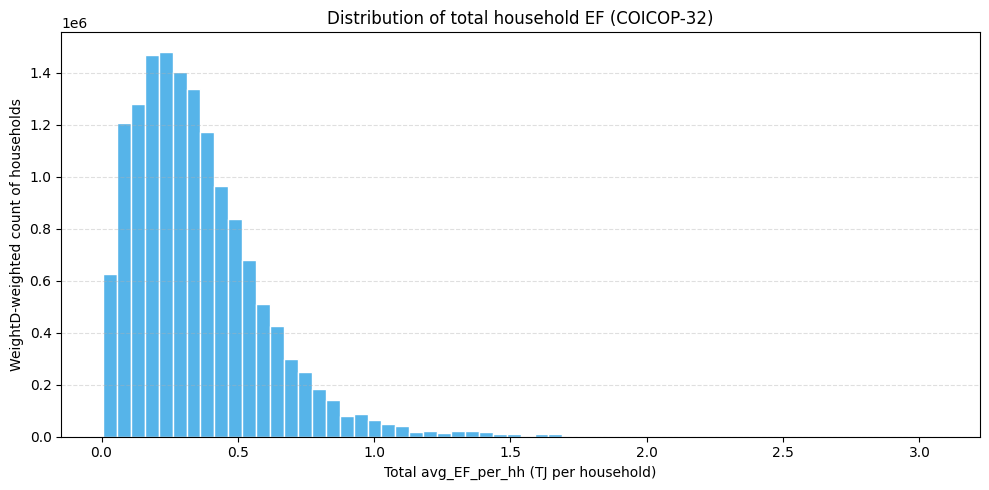

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["avg_EF_per_hh"], bins=60, weights=df["WeightD"],
        color="#56B4E9", edgecolor="white")
ax.set_xlabel("Total avg_EF_per_hh (TJ per household)")
ax.set_ylabel("WeightD-weighted count of households")
ax.set_title(f"Distribution of total household EF (COICOP-{COICOP_LEVEL})")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Scatter — income vs energy footprint

Left panel: household total income (`HH_TotInc`) vs household total EF (`avg_EF_per_hh`), with point sizes proportional to `WeightD` (each survey row represents that many population households).

Right panel: per-capita view — income per OECD-equivalent adult (`HH_TotInc / OECD_scale`) vs per-capita EF (`avg_EF_perOECD_cap`), with point sizes proportional to `OECD_cap`.

A weighted linear-fit line is overlaid on each panel.

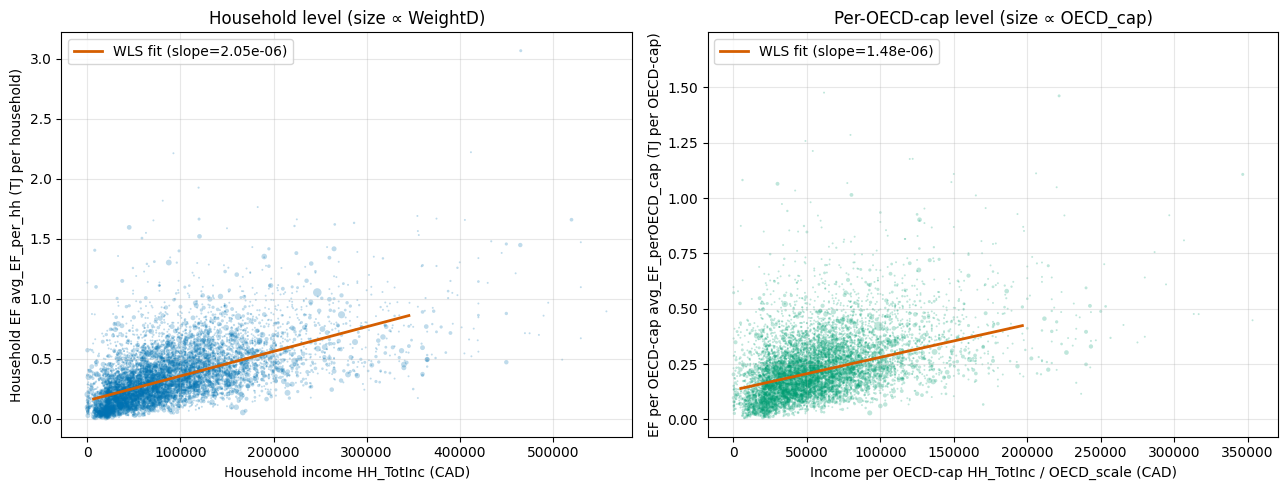

In [7]:
# Build the per-cap income column for the right-hand panel.
_inc_per_cap = df["HH_TotInc"] / df["OECD_scale"]

# Weighted linear fits for the overlay lines.
def _wls_line(x, y, w):
    """Return (slope, intercept) from a 1D weighted LS fit, ignoring NaNs."""
    m = x.notna() & y.notna() & w.notna() & (w > 0)
    if m.sum() < 2:
        return 0.0, 0.0
    return np.polyfit(x[m], y[m], deg=1, w=w[m])

slope_hh, intercept_hh = _wls_line(df["HH_TotInc"], df["avg_EF_per_hh"], df["WeightD"])
slope_pc, intercept_pc = _wls_line(_inc_per_cap, df["avg_EF_perOECD_cap"], df["OECD_cap"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: household-level ---
size_hh = (df["WeightD"] / df["WeightD"].max() * 60).clip(lower=2)
axes[0].scatter(df["HH_TotInc"], df["avg_EF_per_hh"],
                s=size_hh, c="#0072B2", alpha=0.25, edgecolors="none")
x_hh = np.linspace(df["HH_TotInc"].quantile(0.01), df["HH_TotInc"].quantile(0.99), 100)
axes[0].plot(x_hh, slope_hh * x_hh + intercept_hh, color="#D55E00", linewidth=2,
             label=f"WLS fit (slope={slope_hh:.2e})")
axes[0].set_xlabel("Household income HH_TotInc (CAD)")
axes[0].set_ylabel("Household EF avg_EF_per_hh (TJ per household)")
axes[0].set_title("Household level (size ∝ WeightD)")
axes[0].grid(alpha=0.3)
axes[0].legend(loc="upper left")

# --- Right: per-OECD-cap ---
size_pc = (df["OECD_cap"] / df["OECD_cap"].max() * 60).clip(lower=2)
axes[1].scatter(_inc_per_cap, df["avg_EF_perOECD_cap"],
                s=size_pc, c="#009E73", alpha=0.25, edgecolors="none")
x_pc = np.linspace(_inc_per_cap.quantile(0.01), _inc_per_cap.quantile(0.99), 100)
axes[1].plot(x_pc, slope_pc * x_pc + intercept_pc, color="#D55E00", linewidth=2,
             label=f"WLS fit (slope={slope_pc:.2e})")
axes[1].set_xlabel("Income per OECD-cap HH_TotInc / OECD_scale (CAD)")
axes[1].set_ylabel("EF per OECD-cap avg_EF_perOECD_cap (TJ per OECD-cap)")
axes[1].set_title("Per-OECD-cap level (size ∝ OECD_cap)")
axes[1].grid(alpha=0.3)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

## Example — look up a COICOP label

The pickle stores sanitized column names. Use `coicop_label_map` to recover the original COICOP labels:

In [8]:
# Show the first 5 EF-per-hh columns and what they map to
for col in EF_PER_HH_COLS[:5]:
    print(f"{col}  -> {coicop_label_map.get(col, '?')}")

avg_EF_per_hh__C_01_Food_and_non_alcoholic_beverages  -> 01 – Food and non-alcoholic beverages
avg_EF_per_hh__C_02_Alcoholic_beverages_tobacco_and_narcotics  -> 02 – Alcoholic beverages, tobacco and narcotics
avg_EF_per_hh__C_03_Clothing_and_footwear  -> 03 – Clothing and footwear
avg_EF_per_hh__C_04_1_Actual_rentals_for_housing  -> 04.1 Actual rentals for housing
avg_EF_per_hh__C_04_2_Imputed_rentals_for_housing  -> 04.2 Imputed rentals for housing


## Starting points for your analysis

Below are stub cells you can extend. Add cells freely.

- **OLS regression** of `avg_EF_per_hh` on socio-demographics (using `statsmodels`).
- **Inequality decomposition** by income decile, household type, etc.
- **Concentration curves** / **Gini** of EF across deciles.
- **Decomposition** of EF differences (e.g., between deciles) into category contributions.

In [9]:
# Example: weighted OLS - total EF per hh against household income (uncomment to run)
# import statsmodels.api as sm
# X = sm.add_constant(df[["HH_TotInc"]])
# model = sm.WLS(df["avg_EF_per_hh"], X, weights=df["WeightD"]).fit()
# print(model.summary())

## Regression — `avg_EF_perOECD_cap` on socio-economic variables

The outcome `avg_EF_perOECD_cap` is continuous (TJ per OECD-cap), so we use **Weighted Least Squares (WLS)** with `OECD_cap` as the weight — each row contributes proportionally to the number of OECD-equivalent adults it represents (consistent with the per-cap outcome). Categorical predictors are dummy-encoded automatically by the formula API via `C(variable)`. Robust (`HC1`) standard errors handle the heteroskedasticity that's typical of EF data.

The set of predictors covers all socio-economic variables saved in Cell 12 of `Household_EF`.

In [10]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Predictors: all socio-economic categoricals + continuous household income.
_predictors_cat = [
    "Prov", "HHType6", "RP_AgeGrp", "RP_Gender", "RP_MarStat", "RP_Educ",
    "DwelTyp", "Tenure", "NumBedr", "SecResYN", "OthPropYN",
    "InternetYN", "VehicleYN", "HH_MajIncSrc",
]
_required = ["avg_EF_perOECD_cap", "OECD_cap", "HH_TotInc"] + _predictors_cat
df_reg = df.dropna(subset=_required).copy()
print(f"Rows used: {len(df_reg)} / {len(df)} (after dropna)")

formula = (
    "avg_EF_perOECD_cap ~ HH_TotInc + "
    + " + ".join(f"C({c})" for c in _predictors_cat)
)
print("Formula:")
print(" ", formula.replace(" + ", "\n   + "))

Rows used: 7930 / 7930 (after dropna)
Formula:
  avg_EF_perOECD_cap ~ HH_TotInc
   + C(Prov)
   + C(HHType6)
   + C(RP_AgeGrp)
   + C(RP_Gender)
   + C(RP_MarStat)
   + C(RP_Educ)
   + C(DwelTyp)
   + C(Tenure)
   + C(NumBedr)
   + C(SecResYN)
   + C(OthPropYN)
   + C(InternetYN)
   + C(VehicleYN)
   + C(HH_MajIncSrc)


In [11]:
# Weighted OLS (WLS) with OECD_cap as the survey weight and HC1 robust SE.
res_wls = smf.wls(formula, data=df_reg, weights=df_reg["OECD_cap"]).fit(cov_type="HC1")
print(res_wls.summary())
print(f"\nR² (raw)        = {res_wls.rsquared:.4f}")
print(f"R² (adjusted)   = {res_wls.rsquared_adj:.4f}")
print(f"F-statistic     = {res_wls.fvalue:.2f}  (p = {res_wls.f_pvalue:.3g})")
print(f"# observations  = {int(res_wls.nobs)}")
print(f"# parameters    = {len(res_wls.params)}")

                            WLS Regression Results                            
Dep. Variable:     avg_EF_perOECD_cap   R-squared:                       0.347
Model:                            WLS   Adj. R-squared:                  0.344
Method:                 Least Squares   F-statistic:                     779.1
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        14:41:56   Log-Likelihood:                 3134.8
No. Observations:                7930   AIC:                            -6188.
Df Residuals:                    7889   BIC:                            -5902.
Df Model:                          40                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.1475 

c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 43, but rank is 41
  warnings.warn('covariance of constraints does not have full '


### Log-outcome WLS

EF distributions are right-skewed. Modelling `log(avg_EF_perOECD_cap)` often gives a better fit and the coefficients become easier to interpret — they're roughly **% change in EF per unit change in predictor**. A 0.10 coefficient ≈ +10% EF.

We drop rows with zero or negative `avg_EF_perOECD_cap` since `log` is undefined for those.

In [12]:
df_log = df_reg[df_reg["avg_EF_perOECD_cap"] > 0].copy()
df_log["log_EF_perOECD_cap"] = np.log(df_log["avg_EF_perOECD_cap"])
print(f"Rows used: {len(df_log)} / {len(df_reg)}  (zero/neg EF dropped: {len(df_reg) - len(df_log)})")

formula_log = formula.replace("avg_EF_perOECD_cap", "log_EF_perOECD_cap")
res_log = smf.wls(formula_log, data=df_log, weights=df_log["OECD_cap"]).fit(cov_type="HC1")
print(res_log.summary())
print(f"\nR² (raw)        = {res_log.rsquared:.4f}")
print(f"R² (adjusted)   = {res_log.rsquared_adj:.4f}")

Rows used: 7930 / 7930  (zero/neg EF dropped: 0)
                            WLS Regression Results                            
Dep. Variable:     log_EF_perOECD_cap   R-squared:                       0.451
Model:                            WLS   Adj. R-squared:                  0.448
Method:                 Least Squares   F-statistic:                     1942.
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        14:41:57   Log-Likelihood:                -8423.1
No. Observations:                7930   AIC:                         1.693e+04
Df Residuals:                    7889   BIC:                         1.721e+04
Df Model:                          40                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------

c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 43, but rank is 41
  warnings.warn('covariance of constraints does not have full '


### Random Forest baseline

A Random Forest gives you the **upper bound** on R² achievable from these predictors — it captures non-linearities and interactions WLS can't. If RF R² ≈ WLS R², the linear model is doing as well as anything else can. If RF is much higher, there's signal left on the table that linear regression misses (you'd want interactions or non-linear transforms).

This uses sklearn (`pip install scikit-learn` if missing). Pure prediction — no p-values, no inference.

In [13]:
try:
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import cross_val_score

    X_rf = pd.get_dummies(df_reg[["HH_TotInc"] + _predictors_cat], drop_first=True)
    y_rf = df_reg["avg_EF_perOECD_cap"].values
    w_rf = df_reg["OECD_cap"].values

    rf = RandomForestRegressor(
        n_estimators=300, max_depth=None, n_jobs=-1, random_state=42,
    )
    # CV without sample weights — gives an indicative R² on held-out data.
    cv_r2 = cross_val_score(rf, X_rf, y_rf, cv=5, scoring="r2", n_jobs=-1)
    print(f"Random Forest 5-fold CV R² = {cv_r2.mean():.4f} (± {cv_r2.std():.4f})")

    rf.fit(X_rf, y_rf, sample_weight=w_rf)
    importances = pd.Series(rf.feature_importances_, index=X_rf.columns).sort_values(ascending=False)
    print("\nTop 15 features by importance:")
    print(importances.head(15).round(4))
except ImportError:
    print("scikit-learn not installed. Run: pip install scikit-learn")

Random Forest 5-fold CV R² = 0.2771 (± 0.0113)

Top 15 features by importance:
HH_TotInc       0.3006
Tenure_3        0.1559
Prov_35         0.0331
RP_Gender_2     0.0234
SecResYN_2      0.0213
Tenure_2        0.0201
HHType6_2       0.0199
DwelTyp_3       0.0193
RP_Educ_4       0.0192
Prov_48         0.0186
RP_AgeGrp_04    0.0185
DwelTyp_2       0.0184
RP_AgeGrp_03    0.0181
NumBedr_4       0.0180
VehicleYN_2     0.0175
dtype: float64


### Interpretation guide

- **R² (adjusted)** — fraction of variance in EF explained by socio-economic variables. With ~7,900 households and ~40 dummy parameters, expect somewhere between 0.2 and 0.5 for a baseline like this. Higher is better.
- **Each `C(var)[T.<level>]` coefficient** — the effect of being in that category *relative to* the reference level (the omitted level, usually category code 1 or alphabetically first).
- **`HH_TotInc` coefficient** — extra TJ per OECD-cap per CAD of additional household income (very small number, multiply by 1000 or 10000 for readability).
- **P-values** — under `P>|t|`. < 0.05 = statistically significant. With many predictors and ~8k observations, many will be significant; pay attention to coefficient *size*.
- **Compare WLS R² and RF R²** — close → linear model captures the signal. Far apart → there are non-linearities or interactions you could explore.

## Diagnostics — interpreting the Random Forest results

A few quick checks to make sense of what the RF told us:

1. **Tenure descriptive stats** — `Tenure_3` came out at 16% importance. Is "Other" really a big category, or is it a small group with extreme values?
2. **Regrouped importance** — RF importance is per *dummy*. Summing dummies back to their parent variable shows the true ranking.
3. **Direction of effects** — RF doesn't say "more income → more EF". Group-means do.
4. **Interaction WLS** — if linear WLS R² is far below RF R² (~0.28), interactions matter.

### 1. Tenure category distribution and EF means

In [14]:
TENURE_NAMES = {"1": "Owner with mortgage", "2": "Owner without mortgage", "3": "Renter"}

# Count survey rows + WeightD population + EF mean/median per Tenure category
_t = df.groupby("Tenure").agg(
    n_rows     = ("CaseID", "count"),
    n_WeightD  = ("WeightD", "sum"),
    n_OECDcap  = ("OECD_cap", "sum"),
    mean_EF    = ("avg_EF_perOECD_cap", "mean"),
    median_EF  = ("avg_EF_perOECD_cap", "median"),
    std_EF     = ("avg_EF_perOECD_cap", "std"),
)
_t["pct_rows"]    = (_t["n_rows"]    / _t["n_rows"].sum()    * 100).round(1)
_t["pct_WeightD"] = (_t["n_WeightD"] / _t["n_WeightD"].sum() * 100).round(1)
_t.index = [f"{k} - {TENURE_NAMES.get(str(k).strip(), '?')}" for k in _t.index]
print("Tenure distribution and avg_EF_perOECD_cap by category:")
print(_t.round(4))

Tenure distribution and avg_EF_perOECD_cap by category:
                            n_rows     n_WeightD     n_OECDcap  mean_EF  \
1 - Owner with mortgage       3035  5.653969e+06  9.903428e+06   0.2669   
2 - Owner without mortgage    2793  4.232779e+06  6.284230e+06   0.2833   
3 - Renter                    2102  4.842752e+06  6.730640e+06   0.1545   

                            median_EF  std_EF  pct_rows  pct_WeightD  
1 - Owner with mortgage        0.2417  0.1299      38.3         38.4  
2 - Owner without mortgage     0.2479  0.1610      35.2         28.7  
3 - Renter                     0.1299  0.1065      26.5         32.9  


### 2. Regrouped feature importance

Sum the one-hot dummies back to their parent variable, so `Tenure_2` and `Tenure_3` are combined into a single `Tenure` total. This is the importance ranking that actually compares variables on equal footing.

In [15]:
# `importances` was created in the RF cell above. Group by the variable name
# stripped of its dummy suffix (everything after the last underscore).
def _root_var(col):
    # Continuous variables stay as-is; one-hot dummies have an underscore + value suffix.
    if col in ("HH_TotInc",):
        return col
    return col.rsplit("_", 1)[0]

importances_grouped = (
    importances.groupby(_root_var).sum().sort_values(ascending=False)
)
print("Importance by original variable (dummies summed back):")
print(importances_grouped.round(4))

Importance by original variable (dummies summed back):
HH_TotInc       0.3006
Tenure          0.1760
Prov            0.1087
RP_AgeGrp       0.0680
HHType6         0.0614
RP_Educ         0.0497
NumBedr         0.0449
HH_MajIncSrc    0.0449
DwelTyp         0.0376
RP_MarStat      0.0258
RP_Gender       0.0234
SecResYN        0.0213
VehicleYN       0.0175
OthPropYN       0.0129
InternetYN      0.0074
dtype: float64


### 3. Direction of the income effect

RF ranks `HH_TotInc` as the strongest predictor but doesn't say which way it goes. Look at the EF mean across deciles to see if it's monotonic (and how steep).

In [16]:
ef_by_inc = df.groupby("Inc_OECDcap_dec").agg(
    mean_EF    = ("avg_EF_perOECD_cap", "mean"),
    median_EF  = ("avg_EF_perOECD_cap", "median"),
    n_OECDcap  = ("OECD_cap", "sum"),
).sort_index()
print("EF per OECD-cap by per-OECD-cap income decile:")
print(ef_by_inc.round(4))

# Spearman rank correlation (monotonicity)
from scipy.stats import spearmanr
mask = df["Inc_OECDcap_dec"].notna() & df["avg_EF_perOECD_cap"].notna()
rho, p = spearmanr(df.loc[mask, "Inc_OECDcap_dec"], df.loc[mask, "avg_EF_perOECD_cap"])
print(f"\nSpearman rank correlation (Inc_OECDcap_dec vs avg_EF_perOECD_cap): {rho:.4f}  (p = {p:.3g})")

EF per OECD-cap by per-OECD-cap income decile:
                 mean_EF  median_EF     n_OECDcap
Inc_OECDcap_dec                                  
1                 0.1586     0.1254  2.291578e+06
2                 0.1701     0.1511  2.290809e+06
3                 0.1980     0.1697  2.290579e+06
4                 0.2156     0.2001  2.293557e+06
5                 0.2184     0.1952  2.291736e+06
6                 0.2410     0.2221  2.288835e+06
7                 0.2609     0.2376  2.292390e+06
8                 0.2813     0.2562  2.295391e+06
9                 0.3016     0.2779  2.295446e+06
10                0.3870     0.3526  2.287978e+06

Spearman rank correlation (Inc_OECDcap_dec vs avg_EF_perOECD_cap): 0.4757  (p = 0)


### 4. WLS with interactions

Add `HH_TotInc × Tenure` and `HH_TotInc × NumBedr` interactions to the linear model. If R² jumps closer to the RF's 0.28, non-linearity was the story. If it stays put, RF is picking up something the linear form can't capture.

In [17]:
formula_inter = (
    formula
    + " + HH_TotInc:C(Tenure)"
    + " + HH_TotInc:C(NumBedr)"
)
res_inter = smf.wls(formula_inter, data=df_reg, weights=df_reg["OECD_cap"]).fit(cov_type="HC1")
print(f"WLS with interactions:")
print(f"  R² (raw)      = {res_inter.rsquared:.4f}")
print(f"  R² (adjusted) = {res_inter.rsquared_adj:.4f}")
print(f"  F             = {res_inter.fvalue:.2f}")
print(f"  # parameters  = {len(res_inter.params)}")
print(f"\nFor comparison, baseline WLS R²: {res_wls.rsquared:.4f}")
print(f"Random Forest CV R²:               {cv_r2.mean():.4f}")

WLS with interactions:
  R² (raw)      = 0.3493
  R² (adjusted) = 0.3456
  F             = 688.22
  # parameters  = 50

For comparison, baseline WLS R²: 0.3473
Random Forest CV R²:               0.2771


c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 49, but rank is 47
  warnings.warn('covariance of constraints does not have full '


## What explains EF *after* controlling for income and tenure?

Idea: fix the two strongest predictors (`HH_TotInc` and `Tenure`) as a baseline, then test what each other variable adds on top. The variable that increases R² the most explains the largest chunk of *residual* (income-and-tenure-adjusted) variance — i.e. it tells you what differentiates two households that have the same income and tenure status.

In [18]:
# Stepwise check: which variable adds the most explanatory power after income + tenure?
_test_vars = [
    "HHType6", "RP_AgeGrp", "RP_Gender", "RP_MarStat", "RP_Educ",
    "DwelTyp", "NumBedr", "SecResYN", "OthPropYN", "InternetYN",
    "VehicleYN", "HH_MajIncSrc", "Prov",
]

base_formula = "avg_EF_perOECD_cap ~ HH_TotInc + C(Tenure)"
res_base = smf.wls(base_formula, data=df_reg, weights=df_reg["OECD_cap"]).fit(cov_type="HC1")
print(f"Base model (HH_TotInc + Tenure): R² = {res_base.rsquared:.4f}, adj R² = {res_base.rsquared_adj:.4f}\n")

_rows = []
for v in _test_vars:
    f = f"{base_formula} + C({v})"
    res = smf.wls(f, data=df_reg, weights=df_reg["OECD_cap"]).fit(cov_type="HC1")
    var_params = [p for p in res.params.index if p.startswith(f"C({v})")]
    # Joint F-test: are all dummies for `v` simultaneously zero?
    if var_params:
        idx = [res.params.index.get_loc(p) for p in var_params]
        R = np.eye(len(res.params))[idx]
        test = res.wald_test(R, use_f=True)
        f_stat = float(np.array(test.statistic).flat[0])
        p_val  = float(np.array(test.pvalue).flat[0])
    else:
        f_stat, p_val = np.nan, np.nan
    _rows.append({
        "variable":  v,
        "n_levels":  len(var_params),
        "R2_delta":  res.rsquared - res_base.rsquared,
        "R2_total":  res.rsquared,
        "F_joint":   f_stat,
        "p_joint":   p_val,
    })

partial_effects = (
    pd.DataFrame(_rows)
    .sort_values("R2_delta", ascending=False)
    .reset_index(drop=True)
)
print("Each candidate variable added to (HH_TotInc + Tenure), ranked by ΔR²:")
print(partial_effects.round(5).to_string(index=False))

Base model (HH_TotInc + Tenure): R² = 0.2320, adj R² = 0.2317



c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future be

Each candidate variable added to (HH_TotInc + Tenure), ranked by ΔR²:
    variable  n_levels  R2_delta  R2_total  F_joint  p_joint
     HHType6         5   0.02538   0.25738 20.89431  0.00000
HH_MajIncSrc         3   0.01972   0.25172 21.59114  0.00000
     DwelTyp         2   0.01725   0.24925 54.74005  0.00000
     RP_Educ         4   0.01346   0.24546 33.10114  0.00000
   VehicleYN         1   0.01123   0.24323 78.96199  0.00000
    SecResYN         1   0.00984   0.24184 27.61143  0.00000
     NumBedr         4   0.00936   0.24136 27.07125  0.00000
        Prov        10   0.00771   0.23971 14.53295  0.00000
   RP_AgeGrp         5   0.00587   0.23787  5.48470  0.00005
  RP_MarStat         2   0.00428   0.23629  8.86599  0.00014
  InternetYN         1   0.00269   0.23469 17.92122  0.00002
   OthPropYN         1   0.00061   0.23262  2.59914  0.10696
   RP_Gender         1   0.00002   0.23203  0.09653  0.75604


c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
c:\Users\marta.baltruszewicz\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


### Combined model — top contributors

Fit one model with income, tenure, and the five variables that added the most ΔR² above. Coefficients now show each level's effect *holding income, tenure, and the other top vars constant*.

In [19]:
TOP_N = 5
TOP_VARS = partial_effects.head(TOP_N)["variable"].tolist()
combined_formula = (
    "avg_EF_perOECD_cap ~ HH_TotInc + C(Tenure) + "
    + " + ".join(f"C({v})" for v in TOP_VARS)
)
print(f"Combined formula:\n  {combined_formula}\n")

res_combined = smf.wls(combined_formula, data=df_reg,
                       weights=df_reg["OECD_cap"]).fit(cov_type="HC1")
print(res_combined.summary())
print(f"\nBase R²:     {res_base.rsquared:.4f}")
print(f"Combined R²: {res_combined.rsquared:.4f}  (+{res_combined.rsquared - res_base.rsquared:.4f})")

Combined formula:
  avg_EF_perOECD_cap ~ HH_TotInc + C(Tenure) + C(HHType6) + C(HH_MajIncSrc) + C(DwelTyp) + C(RP_Educ) + C(VehicleYN)

                            WLS Regression Results                            
Dep. Variable:     avg_EF_perOECD_cap   R-squared:                       0.321
Model:                            WLS   Adj. R-squared:                  0.320
Method:                 Least Squares   F-statistic:                     109.1
Date:                Wed, 10 Jun 2026   Prob (F-statistic):               0.00
Time:                        14:42:07   Log-Likelihood:                 2979.6
No. Observations:                7930   AIC:                            -5921.
Df Residuals:                    7911   BIC:                            -5789.
Df Model:                          18                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.0

### Pretty effect-size table

Coefficient = TJ per OECD-cap difference vs. the reference (omitted) category, **holding income, tenure, and the other top variables constant**. Significance stars: `*` p<0.05, `**` p<0.01, `***` p<0.001.

Label dictionaries below mirror the labels used in `Household_EF` Cell 9.

In [20]:
LEVEL_NAMES = {
    "Tenure":     {"1": "Owner w/ mortgage", "2": "Owner w/o mortgage", "3": "Renter"},
    "HHType6":    {"1": "One person", "2": "Couple no kids", "3": "Couple w/ kids",
                   "4": "Couple + others", "5": "Lone parent", "6": "Other"},
    "RP_AgeGrp":  {"01": "<30", "02": "30-39", "03": "40-54",
                   "04": "55-64", "05": "65-74", "06": "75+"},
    "RP_Gender":  {"1": "Male", "2": "Female"},
    "RP_MarStat": {"1": "Married/CL", "2": "Widow/Sep/Div", "3": "Single"},
    "RP_Educ":    {"1": "<High school", "2": "High school", "3": "Trade/college",
                   "4": "University", "9": "Not stated"},
    "DwelTyp":    {"1": "Single detached", "2": "Single attached", "3": "Apartment"},
    "NumBedr":    {"1": "1", "2": "2", "3": "3", "4": "4+", "9": "Not stated"},
    "SecResYN":   {"1": "Yes", "2": "No"},
    "OthPropYN":  {"1": "Yes", "2": "No"},
    "InternetYN": {"1": "Yes", "2": "No"},
    "VehicleYN":  {"1": "Yes", "2": "No"},
    "HH_MajIncSrc": {"1": "Wages/salaries", "2": "Self-employment",
                     "3": "Investment/pension", "4": "Govt transfers"},
    "Prov":       {"10": "NL", "11": "PE", "12": "NS", "13": "NB",
                   "24": "QC", "35": "ON", "46": "MB", "47": "SK",
                   "48": "AB", "59": "BC", "63": "Territories"},
}


def _star(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return ""


def _format_var(varname, res):
    rows = []
    for p in res.params.index:
        if not p.startswith(f"C({varname})"):
            continue
        level = p[p.find("[T.") + 3 : p.rfind("]")]
        # statsmodels often appends .0 to int-cast strings — strip if present
        if level.endswith(".0"):
            level = level[:-2]
        label = LEVEL_NAMES.get(varname, {}).get(level, level)
        rows.append({
            "level":      f"{level} ({label})",
            "coef_TJcap": res.params[p],
            "SE":         res.bse[p],
            "p":          res.pvalues[p],
            "sig":        _star(res.pvalues[p]),
        })
    return pd.DataFrame(rows)


print("Effect sizes vs reference category (TJ / OECD-cap), with income + tenure + other top vars held constant:\n")

# Continuous: HH_TotInc
hh_coef = res_combined.params["HH_TotInc"]
hh_se   = res_combined.bse["HH_TotInc"]
hh_p    = res_combined.pvalues["HH_TotInc"]
print(f"HH_TotInc (per CAD of household income):")
print(f"  coef = {hh_coef:+.6g}  SE = {hh_se:.3g}  p = {hh_p:.3g} {_star(hh_p)}")
print(f"  -> +$10k household income -> {hh_coef*10000:+.4f} TJ/cap\n")

# Tenure + each top variable
for v in ["Tenure"] + TOP_VARS:
    tab = _format_var(v, res_combined)
    if tab.empty:
        continue
    print(f"=== {v} (reference = the omitted level) ===")
    print(tab.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
    print()

Effect sizes vs reference category (TJ / OECD-cap), with income + tenure + other top vars held constant:

HH_TotInc (per CAD of household income):
  coef = +5.64417e-07  SE = 5e-08  p = 1.65e-29 ***
  -> +$10k household income -> +0.0056 TJ/cap

=== Tenure (reference = the omitted level) ===
                 level  coef_TJcap      SE       p sig
2 (Owner w/o mortgage)     +0.0113 +0.0059 +0.0525    
            3 (Renter)     -0.0382 +0.0055 +0.0000 ***

=== HHType6 (reference = the omitted level) ===
              level  coef_TJcap      SE       p sig
 2 (Couple no kids)     -0.0278 +0.0058 +0.0000 ***
 3 (Couple w/ kids)     -0.0731 +0.0062 +0.0000 ***
4 (Couple + others)     -0.0910 +0.0110 +0.0000 ***
    5 (Lone parent)     -0.0274 +0.0091 +0.0027  **
          6 (Other)     -0.0593 +0.0075 +0.0000 ***

=== HH_MajIncSrc (reference = the omitted level) ===
                 level  coef_TJcap      SE       p sig
   2 (Self-employment)     +0.0773 +0.0213 +0.0003 ***
3 (Investment/pen

## Where does the archetype gap sit by COICOP category?

For each per-OECD-cap COICOP column, fit a small WLS on the key archetype predictors (income, tenure, household type, income source, dwelling type, education, vehicle ownership) and compute the model-predicted EF for two hypothetical households:

- **High archetype**: one-person, owner-with-mortgage, single detached, self-employed, university-educated, has vehicle, $200k household income.
- **Low archetype**: couple+others, renter, apartment, investment/pension income source, <high-school education, no vehicle, $25k household income.

The difference `high_pred − low_pred` per COICOP category shows where the gap actually accumulates.

In [21]:
# Build the two archetype rows (each is a one-row DataFrame matching df_reg's schema).
# Categorical columns in df_reg are object/string (e.g. HHType6 holds "1".."6",
# not 1..6). Use string values throughout for the archetype rows.
high_arch = pd.DataFrame({
    "HH_TotInc":   [200000.0],
    "Tenure":      ["1"],   # Owner w/ mortgage
    "HHType6":     ["1"],   # One person
    "HH_MajIncSrc":["2"],   # Self-employment
    "DwelTyp":     ["1"],   # Single detached
    "RP_Educ":     ["4"],   # University
    "VehicleYN":   ["1"],   # Yes
})
low_arch = pd.DataFrame({
    "HH_TotInc":   [25000.0],
    "Tenure":      ["3"],   # Renter
    "HHType6":     ["4"],   # Couple + others
    "HH_MajIncSrc":["3"],   # Investment/pension
    "DwelTyp":     ["3"],   # Apartment
    "RP_Educ":     ["1"],   # <High school
    "VehicleYN":   ["2"],   # No
})

# Ensure archetype dtypes match df_reg (patsy needs exact-level matches for C(...)).
for col in [c for c in low_arch.columns if c != "HH_TotInc"]:
    target_dtype = df_reg[col].dtype
    high_arch[col] = high_arch[col].astype(target_dtype)
    low_arch[col]  = low_arch[col].astype(target_dtype)

KEY_FORMULA_RHS = (
    "HH_TotInc + C(Tenure) + C(HHType6) + C(HH_MajIncSrc) "
    "+ C(DwelTyp) + C(RP_Educ) + C(VehicleYN)"
)

rows = []
for col in EF_PER_CAP_COLS:
    res_c = smf.wls(f"{col} ~ {KEY_FORMULA_RHS}",
                    data=df_reg, weights=df_reg["OECD_cap"]).fit()
    hi = float(res_c.predict(high_arch).iloc[0])
    lo = float(res_c.predict(low_arch).iloc[0])
    rows.append({
        "coicop":    coicop_label_map.get(col, col)[:50],   # human-readable, truncated
        "high":      hi,
        "low":       lo,
        "diff":      hi - lo,
        "pct_diff":  (hi - lo) / lo * 100 if lo > 0 else float("nan"),
        "share_of_gap": None,   # filled below
    })

arch_decomp = pd.DataFrame(rows)
arch_decomp["share_of_gap"] = arch_decomp["diff"] / arch_decomp["diff"].sum() * 100
arch_decomp = arch_decomp.sort_values("diff", ascending=False).reset_index(drop=True)

print("Per-COICOP archetype gap (high − low), sorted largest first:\n")
print(arch_decomp.head(15).round(4).to_string(index=False))

print(f"\nSum of all diffs:                      {arch_decomp['diff'].sum():.4f} TJ/cap")
print(f"Population mean avg_EF_perOECD_cap:    {df_reg['avg_EF_perOECD_cap'].mean():.4f} TJ/cap")
print(f"High archetype predicted total EF:     {arch_decomp['high'].sum():.4f} TJ/cap")
print(f"Low archetype predicted total EF:      {arch_decomp['low'].sum():.4f} TJ/cap")

Per-COICOP archetype gap (high − low), sorted largest first:

                                            coicop   high     low   diff  pct_diff  share_of_gap
                             09.6 Package holidays 0.0705 -0.0179 0.0884       NaN       18.2294
                                          04.5 gas 0.0627 -0.0183 0.0810       NaN       16.7139
    07.2 Operation of personal transport equipment 0.0515 -0.0088 0.0603       NaN       12.4369
                           07.3 Transport services 0.0649  0.0100 0.0549  552.1393       11.3354
                                 04.5 Electricity, 0.0476  0.0027 0.0448 1648.3800        9.2530
                        12.7 Other services n.e.c. 0.0272 -0.0017 0.0289       NaN        5.9623
     05.5 Tools and equipment for house and garden 0.0202 -0.0027 0.0229       NaN        4.7247
                  04.2 Imputed rentals for housing 0.0105 -0.0016 0.0121       NaN        2.5019
                             04.5  and other fuels 0.0125  0.0010

### Visualise the gap by COICOP

Horizontal bar chart, sorted by absolute contribution. Positive bars = the high archetype consumes more in that category; negative bars = the low archetype consumes more (rare but possible).

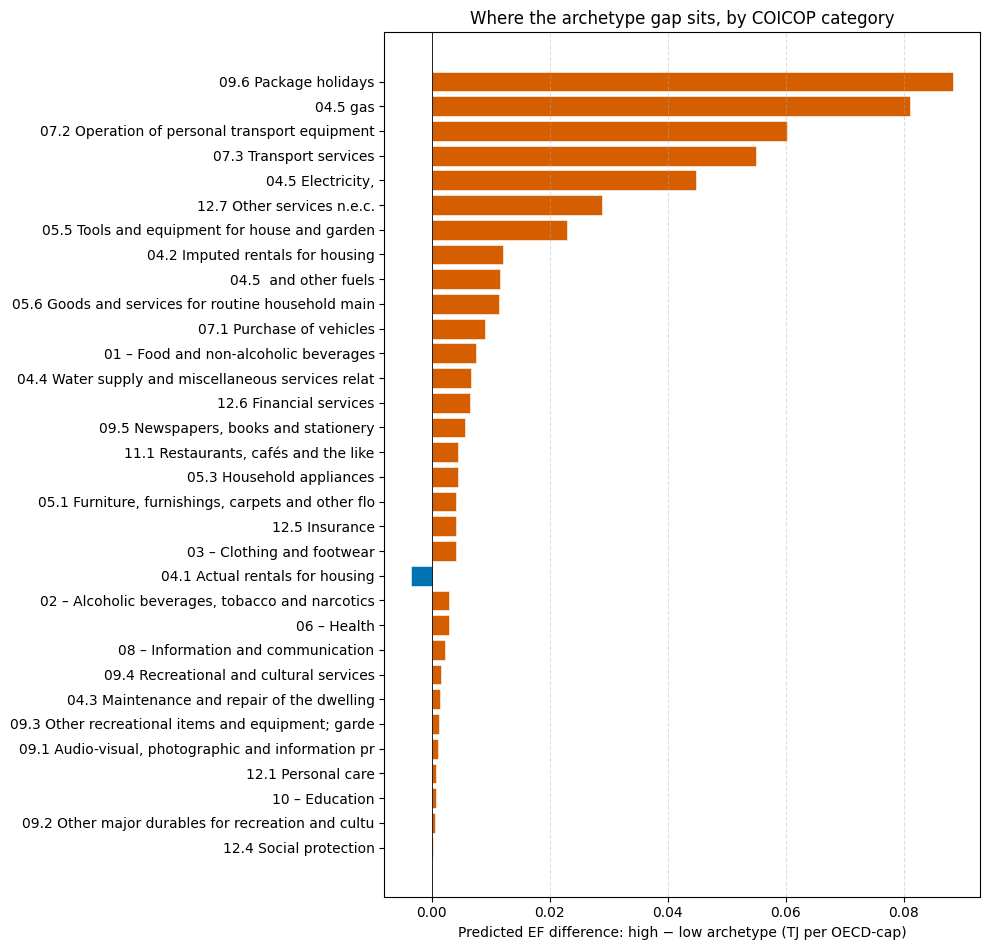

In [22]:
# Sort by absolute gap so the biggest contributors are at the top of the chart.
plot_df = arch_decomp.copy()
plot_df["abs_diff"] = plot_df["diff"].abs()
plot_df = plot_df.sort_values("abs_diff", ascending=True)   # ascending → biggest on top in barh

fig, ax = plt.subplots(figsize=(10, max(6, 0.3 * len(plot_df))))
colors = ["#D55E00" if d >= 0 else "#0072B2" for d in plot_df["diff"]]
ax.barh(plot_df["coicop"], plot_df["diff"], color=colors, edgecolor="white", linewidth=0.4)
ax.axvline(0, color="black", linewidth=0.6)
ax.set_xlabel("Predicted EF difference: high − low archetype (TJ per OECD-cap)")
ax.set_title("Where the archetype gap sits, by COICOP category")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Concentration check

What share of the total gap is concentrated in the top few categories?

In [23]:
cumulative = arch_decomp.copy()
cumulative["cum_share"] = cumulative["share_of_gap"].cumsum()
print("Top categories cumulating to ~80% of the gap:")
print(cumulative[["coicop", "diff", "share_of_gap", "cum_share"]].head(15).round(2).to_string(index=False))

top3_share = cumulative.head(3)["share_of_gap"].sum()
top5_share = cumulative.head(5)["share_of_gap"].sum()
print(f"\nTop 3 categories explain ~{top3_share:.1f}% of the high-vs-low gap.")
print(f"Top 5 categories explain ~{top5_share:.1f}% of the high-vs-low gap.")

Top categories cumulating to ~80% of the gap:
                                            coicop  diff  share_of_gap  cum_share
                             09.6 Package holidays  0.09         18.23      18.23
                                          04.5 gas  0.08         16.71      34.94
    07.2 Operation of personal transport equipment  0.06         12.44      47.38
                           07.3 Transport services  0.05         11.34      58.72
                                 04.5 Electricity,  0.04          9.25      67.97
                        12.7 Other services n.e.c.  0.03          5.96      73.93
     05.5 Tools and equipment for house and garden  0.02          4.72      78.66
                  04.2 Imputed rentals for housing  0.01          2.50      81.16
                             04.5  and other fuels  0.01          2.38      83.53
05.6 Goods and services for routine household main  0.01          2.36      85.89
                         07.1 Purchase of vehicles  